# 05 — Modello ibrido: fisica + apprendimento

**Idea** (dalla fisica delle particelle: calcolare a mano le masse invarianti prima della regressione rende
il lavoro della rete più facile). La rete riceve la serie grezza **e** le stime fisiche, e impara a
**correggerle** invece di partire da zero.

**Disegno 2×2 (D-12)** — tutte le celle sullo stesso test set:

| | senza feature fisiche | con feature fisiche |
|---|---|---|
| **senza serie grezza** | 0 baseline | modello sulle feature (GBT/MLP, notebook 03; qui anche sui soli 4 stimatori) |
| **con serie grezza** | CNN (notebook 03) | **CNN ibrida** (questo notebook) |

più gli stimatori fisici da soli (DFA grezza e ricalibrata).

**Varianti dell'ibrido**
- **ibrido-min**: la CNN riceve le 4 stime fisiche del piano originale — $\hat H_{\rm DFA}$, $\hat H_{R/S}$,
  $\gamma$ della NVG, $\lambda$ della HVG;
- **ibrido-full**: la CNN riceve tutte le 42 feature (curve DFA e R/S + 16 feature del grafo);
- **ibrido-full-int**: come ibrido-full, ma con le 32 feature indipendenti da $N$ e dall'ampiezza (D-30,
  notebook 03: stime, pendenze locali, livelli a scale assolute $s = 8, 16, 32$, grafo);
- **ibrido-residuo**: come ibrido-min, ma la rete predice la correzione $H - \hat H_{\rm DFA}$;
- **GNN ibrida**: la variante migliore della GNN (notebook 04) con le 4 stime fisiche.

Le feature entrano concatenate alla rappresentazione appresa, subito prima della testa densa (fusione tardiva).
Architettura, iperparametri e seed sono **identici** a quelli della rete senza feature: l'unica differenza è
l'input aggiuntivo (D-36). È questo che rende l'ablazione pulita.

**Contenuto:** 1. Configurazione · 2. Feature fisiche · 3. Modelli sulle sole 4 stime · 4. CNN ibride ·
5. GNN ibrida · 6. Tabella 2×2 e confronto · 7. Quanto si appoggia l'ibrido alla fisica? · 8. Robustezza in $N$ ·
9. Salvataggio · 10. Riepilogo

In [1]:
# --- Setup: su Colab clona il repository; ovunque installa ciò che manca ---
import os, sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Arminas00/stochastic-ml.git"
if IN_COLAB:
    repo = "/content/stochastic-ml"
    if os.path.exists(repo):
        subprocess.run(["git", "-C", repo, "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo], check=True)
    os.chdir(repo)

needed = ["numpy", "scipy", "pandas", "matplotlib", "sklearn", "ts2vg", "torch", "torch_geometric"]
missing = [m for m in needed if importlib.util.find_spec(m) is None]
if missing:
    print("Installo:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())
print("Cartella di lavoro:", os.getcwd(), "| Colab:", IN_COLAB)

Cartella di lavoro: C:\Users\user\Downloads\AI_Project\stochastic-ml | Colab: False


## 1. Configurazione

Gli iperparametri non si cercano di nuovo: si riusano quelli scelti nei notebook 03 e 04 (letti dai pesi salvati).

In [2]:
MODE = "quick"
SEED = 2026
DATA_DIR = "data"
FIG_DIR = "figures"
N_BOOT = 1000

if MODE == "quick":
    N_SEEDS, N_SEEDS_GNN = 3, 2
    TRAIN_KW = dict(max_epochs=15, patience=5, batch_size=128, lr=2e-3)       # come notebook 03
    GNN_TRAIN_KW = dict(max_epochs=12, patience=4, batch_size=128, lr=1e-3)   # come notebook 04
else:
    N_SEEDS, N_SEEDS_GNN = 5, 5
    TRAIN_KW = dict(max_epochs=40, patience=6, batch_size=128, lr=1e-3)
    GNN_TRAIN_KW = dict(max_epochs=40, patience=6, batch_size=128, lr=1e-3)
GBT_GRID = [dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15),
            dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=31)]

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import HistGradientBoostingRegressor

import sp_utils as u

u.set_seed(SEED)
Path(FIG_DIR).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def savefig(name):
    plt.savefig(f"{FIG_DIR}/05_{name}.png", bbox_inches="tight", dpi=150)

DEV = u.get_device()
CFG = u.MODES[MODE]
ds = u.load_or_make_fbm_dataset(MODE, SEED, DATA_DIR)
feats = u.load_or_make_features(ds, MODE, SEED, DATA_DIR)
SPLITS = list(ds)
H = {s: ds[s]["H"].astype(np.float64) for s in SPLITS}

# Iperparametri dei notebook precedenti, letti dai pesi salvati
cnn_states = torch.load(Path(DATA_DIR) / f"cnn03_{MODE}_seed{SEED}.pt", map_location="cpu")
CNN_HP = dict(width=int(cnn_states["per_serie"][0]["features.0.weight"].shape[0]))
gnn_states = torch.load(Path(DATA_DIR) / f"gnn04_{MODE}_seed{SEED}.pt", map_location="cpu")
print("Dispositivo:", DEV, "| CNN:", CNN_HP)

Dispositivo: cpu | CNN: {'width': 8}


## 2. Feature fisiche

Le stesse del notebook 02/03, standardizzate con media e deviazione del **train** (valori mancanti → mediana del train).
Sono funzioni della sola serie: usarle come input non introduce alcuna informazione sul vero $H$.

In [4]:
col = {n: j for j, n in enumerate(u.GRAPH_FEATURES)}
def phys(f, X, group):
    if group == "min":
        return np.column_stack([f["dfa"], f["rs"], f["graph"][:, col["nvg_fbm_gamma"]], f["graph"][:, col["hvg_fgn_lambda"]]])
    if group == "full-int":     # versione indipendente da N (D-30): come "tutte-int" del notebook 03
        return np.column_stack([u.classic_intensive_features(f, X), f["graph"]])
    return np.column_stack([f["dfa"], f["rs"], f["logF"], f["logRS"], f["graph"]])

E = {}
for group in ["min", "full", "full-int"]:
    raw = {s: phys(feats[s], ds[s]["X"], group) for s in SPLITS}
    sc = u.FeatureScaler().fit(raw["train"])
    E[group] = {s: sc.transform(raw[s]) for s in SPLITS}
    print(f"ibrido-{group}: {E[group]['train'].shape[1]} feature fisiche")
XN = {s: u.normalize_series(ds[s]["X"], "per_serie") for s in SPLITS}
DFA = {s: feats[s]["dfa"] for s in SPLITS}

ibrido-min: 4 feature fisiche
ibrido-full: 42 feature fisiche
ibrido-full-int: 32 feature fisiche


## 3. Modello sulle sole 4 stime fisiche

Per completare la cella "senza serie, con feature" anche per ibrido-min: gradient boosting sulle 4 stime.
Risponde a "quanto si guadagna combinando gli stimatori fisici, senza guardare la serie?".

In [5]:
PRED, PRED_STD, MEMBER_RMSE, TIMES = {}, {}, {}, {}
best = None
for hp in GBT_GRID:
    g = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **hp).fit(E["min"]["train"], H["train"])
    val = u.regression_metrics(H["val"], g.predict(E["min"]["val"]))["RMSE"]
    print(hp, f"RMSE val {val:.4f}")
    if best is None or val < best[1]:
        best = (hp, val, g)
PRED["5-GBT 4 stime fisiche"] = {s: best[2].predict(E["min"][s]) for s in SPLITS}

{'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 15} RMSE val 0.0471


{'max_iter': 600, 'learning_rate': 0.05, 'max_leaf_nodes': 31} RMSE val 0.0489


## 4. CNN ibride

Stessa CNN del notebook 03 (stessa larghezza, stessi seed, stesso addestramento), con `n_extra` feature
concatenate prima della testa densa. Per la variante a residuo il target è $H - \hat H_{\rm DFA}$ e la previsione
finale è $\hat H_{\rm DFA}$ + uscita della rete; l'RMSE sul residuo coincide con l'RMSE su $H$.

In [6]:
def fit_ensemble(name, make_model, Xs, target, extra, n_seeds, train_kw, offset=None):
    """Addestra n_seeds modelli; salva media e deviazione delle previsioni (+ offset per il residuo)."""
    t0 = time.time()
    members = []
    for k in range(n_seeds):
        m, _ = u.train_regressor(make_model(), Xs["train"], target["train"], Xs["val"], target["val"],
                                 E_tr=extra["train"] if extra else None, E_val=extra["val"] if extra else None,
                                 seed=SEED + 100 * k, **train_kw)
        members.append(m)
    TIMES[name] = time.time() - t0
    P = {s: np.stack([u.predict(m, Xs[s], extra[s] if extra else None) for m in members])
         + (offset[s] if offset else 0) for s in SPLITS}
    PRED[name] = {s: P[s].mean(0) for s in SPLITS}
    PRED_STD[name] = {s: P[s].std(0) for s in SPLITS}
    MEMBER_RMSE[name] = [u.regression_metrics(H["val"], P["val"][k])["RMSE"] for k in range(n_seeds)]
    print(f"{name:<32} membri (val) {np.round(MEMBER_RMSE[name], 4)}  ensemble (val) "
          f"{u.regression_metrics(H['val'], PRED[name]['val'])['RMSE']:.4f}  ({TIMES[name]:.0f} s)")
    return members

HYB = {}
for group in ["min", "full", "full-int"]:
    n_extra = E[group]["train"].shape[1]
    HYB[group] = fit_ensemble(f"5 CNN ibrida-{group}", lambda: u.build_model("cnn", n_extra=n_extra, **CNN_HP),
                              XN, H, E[group], N_SEEDS, TRAIN_KW)
resid = {s: H[s] - DFA[s] for s in SPLITS}
HYB["residuo"] = fit_ensemble("5 CNN ibrida-residuo", lambda: u.build_model("cnn", n_extra=4, **CNN_HP),
                              XN, resid, E["min"], N_SEEDS, TRAIN_KW, offset=DFA)

5 CNN ibrida-min                 membri (val) [0.0337 0.0391 0.0338]  ensemble (val) 0.0327  (98 s)


5 CNN ibrida-full                membri (val) [0.0262 0.0268 0.0267]  ensemble (val) 0.0257  (123 s)


5 CNN ibrida-full-int            membri (val) [0.0295 0.03   0.0295]  ensemble (val) 0.0290  (122 s)


5 CNN ibrida-residuo             membri (val) [0.0367 0.0378 0.0383]  ensemble (val) 0.0352  (82 s)


## 5. GNN ibrida

Si sceglie la variante della GNN migliore **sul validation** (notebook 04) e la si riaddestra identica con in più
le 4 stime fisiche.

In [7]:
p04 = np.load(Path(DATA_DIR) / f"preds04_{MODE}_seed{SEED}.npz")
gnn_names = sorted({k.split("__")[0] for k in p04.files if not k.startswith("STD::")})
val_rmse = {n: u.regression_metrics(H["val"], p04[f"{n}__val"])["RMSE"] for n in gnn_names}
display(pd.Series(val_rmse, name="RMSE val").round(4))
BEST_GNN = min(val_rmse, key=val_rmse.get)
print("Variante scelta:", BEST_GNN)

kind, series = ("nvg", "fbm") if "NVG" in BEST_GNN else ("hvg", "fgn")
which = "grado+valori" if "valori" in BEST_GNN else "grado"
st = gnn_states[BEST_GNN][0]
GNN_HP = dict(hidden=int(st["convs.0.nn.0.weight"].shape[0]),
              n_layers=len({k.split(".")[1] for k in st if k.startswith("convs.")}))
print("Iperparametri GNN:", GNN_HP)

t0 = time.time()
graphs = {s: u.build_graphs(ds[s]["X"], kind, series) for s in SPLITS}
lk = np.log(np.concatenate(graphs["train"][1]))
G = {s: u.GraphSet(graphs[s][0], u.node_features(graphs[s][1], graphs[s][2], which, lk.mean(), lk.std())) for s in SPLITS}
n_in = G["train"].x[0].shape[1]
print(f"Grafi costruiti in {time.time() - t0:.0f} s")
fit_ensemble(f"5 GNN ibrida ({BEST_GNN.replace('4 GNN ', '')})",
             lambda: u.build_gnn(n_in=n_in, n_extra=4, **GNN_HP), G, H, E["min"], N_SEEDS_GNN, GNN_TRAIN_KW)
GNN_HYB = f"5 GNN ibrida ({BEST_GNN.replace('4 GNN ', '')})"

4 GNN HVG(fGn) grado           0.0880
4 GNN HVG(fGn) grado+valori    0.0375
4 GNN NVG(fBm) grado           0.0546
4 GNN NVG(fBm) grado+valori    0.0464
Name: RMSE val, dtype: float64

Variante scelta: 4 GNN HVG(fGn) grado+valori
Iperparametri GNN: {'hidden': 64, 'n_layers': 3}


Grafi costruiti in 6 s


C:\Users\user\Downloads\AI_Project\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


5 GNN ibrida (HVG(fGn) grado+valori) membri (val) [0.0365 0.0379]  ensemble (val) 0.0366  (385 s)


## 6. Tabella 2×2 e confronto sul test

In [8]:
p02 = np.load(Path(DATA_DIR) / f"preds02_{MODE}_seed{SEED}.npz")
p03 = np.load(Path(DATA_DIR) / f"preds03_{MODE}_seed{SEED}.npz")
for ref, src in [("0 baseline (media)", p02), ("1a DFA", p02), ("1a-cal DFA ricalibrata", p02),
                 ("3-GBT feature tutte", p03), ("3-GBT feature tutte-int", p03), ("3 CNN (per_serie)", p03)]:
    PRED[ref] = {s: src[f"{ref}__{s}"] for s in SPLITS}
PRED[BEST_GNN] = {s: p04[f"{BEST_GNN}__{s}"] for s in SPLITS}

order = ["0 baseline (media)", "1a DFA", "1a-cal DFA ricalibrata", "5-GBT 4 stime fisiche", "3-GBT feature tutte",
         "3-GBT feature tutte-int", "3 CNN (per_serie)", "5 CNN ibrida-min", "5 CNN ibrida-full", "5 CNN ibrida-full-int",
         "5 CNN ibrida-residuo", BEST_GNN, GNN_HYB]
rows = []
for name in order:
    m = u.regression_metrics(H["test"], PRED[name]["test"])
    lo, hi = u.bootstrap_ci(H["test"], PRED[name]["test"], "RMSE", n_boot=N_BOOT, seed=SEED)
    rows.append({"metodo": name, "RMSE": m["RMSE"], "IC 95% RMSE": f"[{lo:.4f}, {hi:.4f}]", "MAE": m["MAE"],
                 "bias": m["bias"], "R2": m["R2"], "std previsioni": m["std previsioni"]})
df_res = pd.DataFrame(rows).set_index("metodo")
display(df_res.round(4))

,RMSE,IC 95% RMSE,MAE,bias,R2,std previsioni
metodo,,,,,,
0 baseline (media),0.2591,"[0.2539, 0.2637]",0.2234,0.0001,-0.0000,0.0000
1a DFA,0.0533,"[0.0514, 0.0552]",0.0414,0.0049,0.9577,0.2524
1a-cal DFA ricalibrata,0.0531,"[0.0512, 0.0551]",0.0406,-0.0020,0.9580,0.2527
5-GBT 4 stime fisiche,0.0446,"[0.0429, 0.0461]",0.0342,-0.0016,0.9704,0.2550
3-GBT feature tutte,0.0263,"[0.0254, 0.0273]",0.0203,-0.0001,0.9897,0.2584
3-GBT feature tutte-int,0.0299,"[0.0290, 0.0310]",0.0235,-0.0007,0.9866,0.2572
3 CNN (per_serie),0.0308,"[0.0299, 0.0318]",0.0244,-0.0055,0.9858,0.2602
5 CNN ibrida-min,0.0319,"[0.0310, 0.0329]",0.0258,0.0071,0.9849,0.2521
5 CNN ibrida-full,0.0256,"[0.0247, 0.0264]",0.0202,-0.0018,0.9903,0.2567


In [9]:
R = df_res["RMSE"]
table = pd.DataFrame({
    "senza feature fisiche": [f"baseline: {R['0 baseline (media)']:.4f}",
                              f"CNN: {R['3 CNN (per_serie)']:.4f}"],
    "con 4 stime fisiche": [f"GBT su 4 stime: {R['5-GBT 4 stime fisiche']:.4f}",
                            f"CNN ibrida-min: {R['5 CNN ibrida-min']:.4f}  (residuo: {R['5 CNN ibrida-residuo']:.4f})"],
    "con 42 feature fisiche": [f"GBT su 42 feature: {R['3-GBT feature tutte']:.4f}",
                               f"CNN ibrida-full: {R['5 CNN ibrida-full']:.4f}"],
    "con 32 feature indipendenti da N": [f"GBT su 32 feature: {R['3-GBT feature tutte-int']:.4f}",
                                         f"CNN ibrida-full-int: {R['5 CNN ibrida-full-int']:.4f}"],
}, index=["senza serie grezza", "con serie grezza"])
print(f"Solo fisica, nessun apprendimento: DFA {R['1a DFA']:.4f} (ricalibrata {R['1a-cal DFA ricalibrata']:.4f})")
print(f"GNN: {BEST_GNN} {R[BEST_GNN]:.4f}  ->  ibrida {R[GNN_HYB]:.4f}")
display(table)

Solo fisica, nessun apprendimento: DFA 0.0533 (ricalibrata 0.0531)
GNN: 4 GNN HVG(fGn) grado+valori 0.0361  ->  ibrida 0.0352


,senza feature fisiche,con 4 stime fisiche,con 42 feature fisiche,con 32 feature indipendenti da N
senza serie grezza,baseline: 0.2591,GBT su 4 stime: 0.0446,GBT su 42 feature: 0.0263,GBT su 32 feature: 0.0299
con serie grezza,CNN: 0.0308,CNN ibrida-min: 0.0319 (residuo: 0.0336),CNN ibrida-full: 0.0256,CNN ibrida-full-int: 0.0286


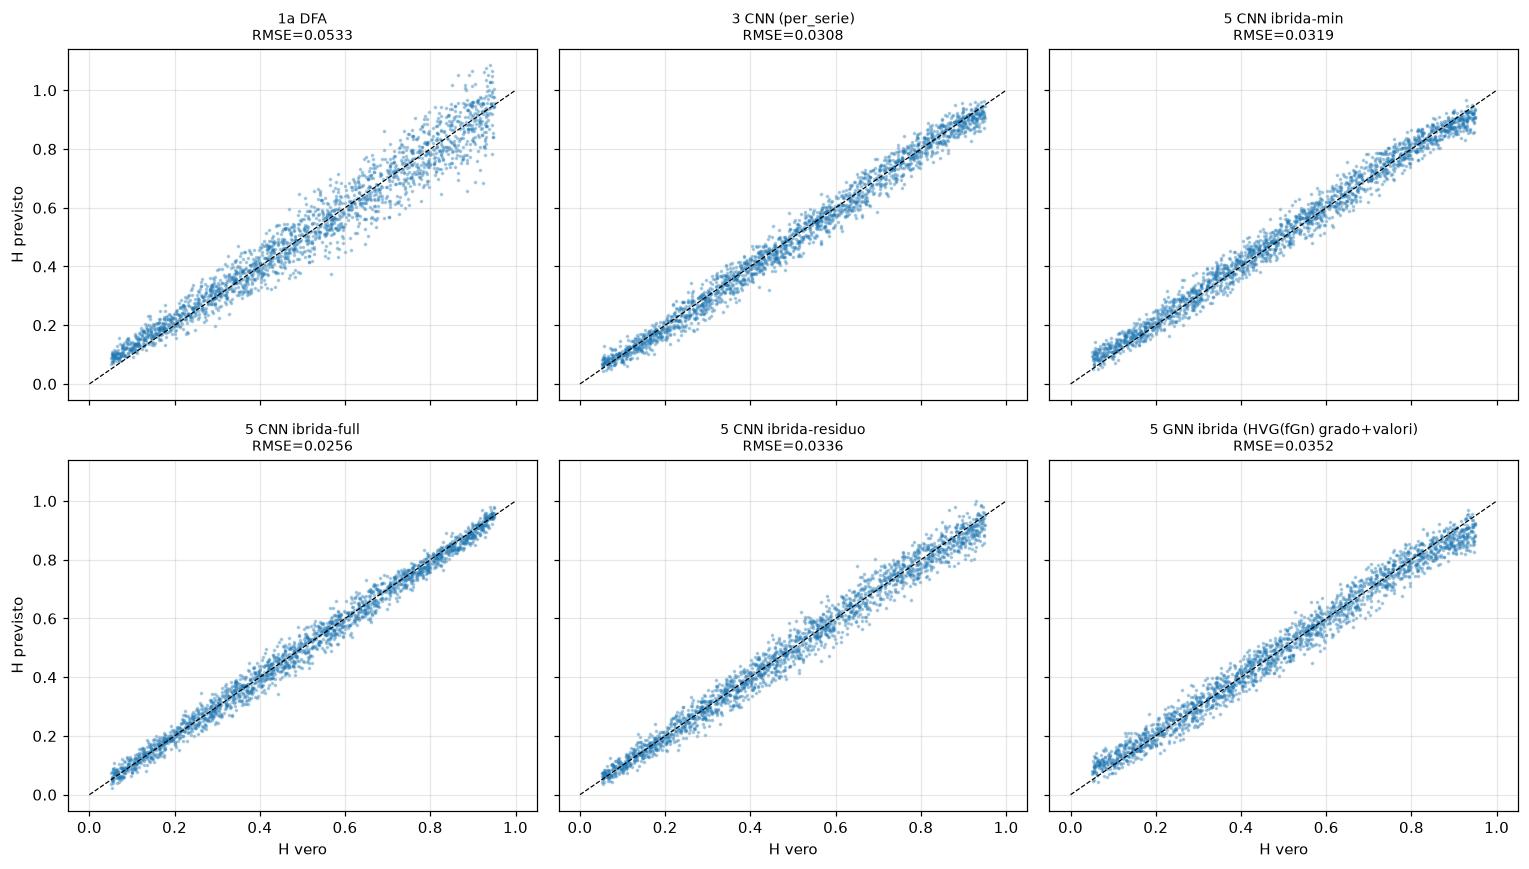

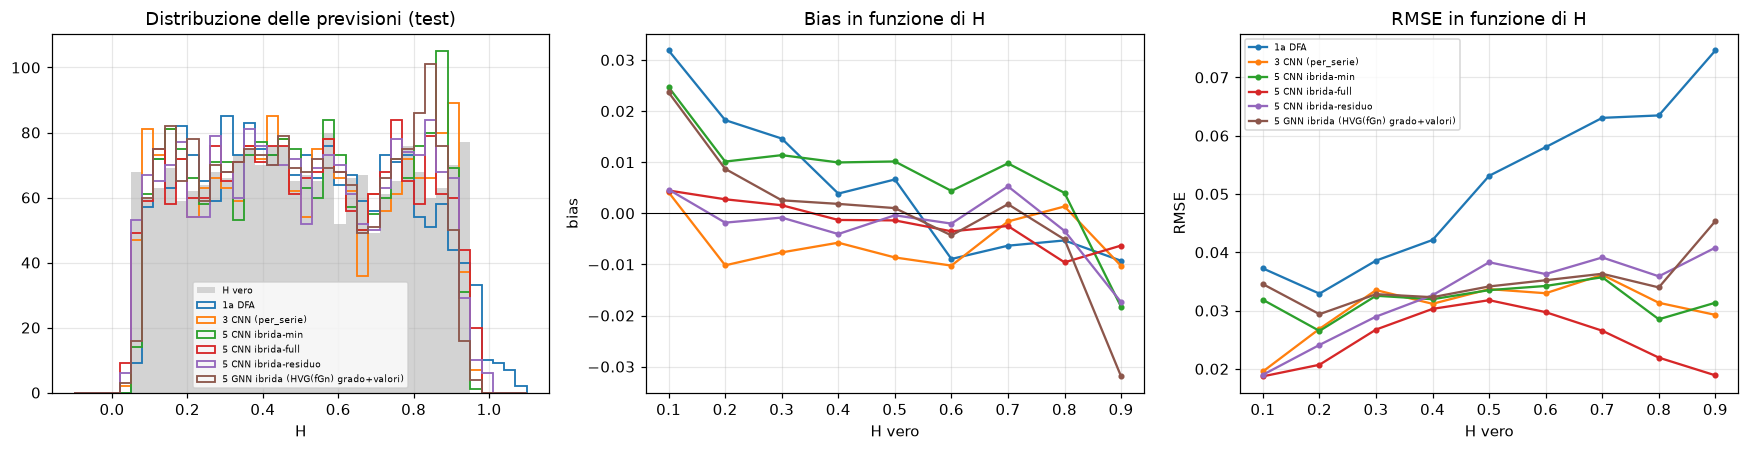

In [10]:
show = ["1a DFA", "3 CNN (per_serie)", "5 CNN ibrida-min", "5 CNN ibrida-full", "5 CNN ibrida-residuo", GNN_HYB]
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, show):
    ax.scatter(H["test"], PRED[name]["test"], s=2, alpha=0.3)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}\nRMSE={R[name]:.4f}", fontsize=9)
for ax in axes[-1]: ax.set_xlabel("H vero")
for ax in axes[:, 0]: ax.set_ylabel("H previsto")
plt.tight_layout(); savefig("scatter"); plt.show()

bins = np.linspace(0.05, 0.95, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(H["test"], bins=40, range=(-0.1, 1.1), histtype="stepfilled", color="lightgrey", label="H vero")
for name in show:
    axes[0].hist(PRED[name]["test"], bins=40, range=(-0.1, 1.1), histtype="step", lw=1.2, label=name)
    be = u.binned_errors(H["test"], PRED[name]["test"], bins)
    axes[1].plot(be["centers"], be["bias"], "o-", ms=3, label=name)
    axes[2].plot(be["centers"], be["rmse"], "o-", ms=3, label=name)
axes[0].set(xlabel="H", title="Distribuzione delle previsioni (test)"); axes[0].legend(fontsize=6)
axes[1].axhline(0, color="k", lw=0.7); axes[1].set(xlabel="H vero", ylabel="bias", title="Bias in funzione di H")
axes[2].set(xlabel="H vero", ylabel="RMSE", title="RMSE in funzione di H"); axes[2].legend(fontsize=6)
plt.tight_layout(); savefig("errore_vs_H"); plt.show()

## 7. Quanto si appoggia l'ibrido alla fisica?

**Test di permutazione.** Sul test set rimescoliamo a caso, tra le serie, una feature fisica alla volta (la serie
grezza resta al suo posto) e misuriamo quanto peggiora l'RMSE. Se l'ibrido ignorasse la fisica, l'RMSE non
cambierebbe; se dipendesse solo da essa, crescerebbe molto. Rimescoliamo anche tutte le feature insieme:
l'ibrido degrada con grazia (la serie grezza basta ancora) o crolla?

In [11]:
rng_p = np.random.default_rng(SEED + 55)
names_min = ["H DFA", "H R/S", "gamma NVG(fBm)", "lambda HVG(fGn)"]
def ens_rmse(members, Xs, Es, offset=0):
    p = np.mean([u.predict(m, Xs, Es) for m in members], axis=0) + offset
    return u.regression_metrics(H["test"], p)["RMSE"]

rows = []
for label, key, off in [("ibrida-min", "min", 0), ("ibrida-residuo", "residuo", DFA["test"])]:
    Et = E["min"]["test"]
    base = ens_rmse(HYB[key], XN["test"], Et, off)
    r = {"modello": label, "RMSE": base}
    for j, fn in enumerate(names_min):
        Ep = Et.copy(); Ep[:, j] = rng_p.permutation(Ep[:, j])
        r[f"rimescolata: {fn}"] = ens_rmse(HYB[key], XN["test"], Ep, off)
    r["rimescolate tutte"] = ens_rmse(HYB[key], XN["test"], rng_p.permutation(Et), off)
    rows.append(r)
df_perm = pd.DataFrame(rows).set_index("modello")
display(df_perm.round(4))

,RMSE,rimescolata: H DFA,rimescolata: H R/S,rimescolata: gamma NVG(fBm),rimescolata: lambda HVG(fGn),rimescolate tutte
modello,,,,,,
ibrida-min,0.0319,0.0596,0.0624,0.0320,0.0406,0.1212
ibrida-residuo,0.0336,0.0408,0.0369,0.0336,0.0353,0.0444


*Nota sulla variante a residuo.* Rimescolando le feature non si rimescola l'offset $\hat H_{\rm DFA}$ aggiunto
all'uscita: la variante a residuo resta comunque ancorata alla DFA della serie giusta.

## 8. Robustezza rispetto a $N$

Le feature dell'ibrido-full contengono le curve DFA/R-S su scale relative a $N$ (D-30): ci aspettiamo che
l'ibrido-full erediti questo limite. L'ibrido-min usa solo pendenze ed esponenti, l'ibrido-full-int le feature
costruite per essere indipendenti da $N$.

N,128,256,512,1024,2048
metodo,,,,,
1a DFA,0.101,0.072,0.053,0.040,0.034
3 CNN (per_serie),0.079,0.048,0.031,0.028,0.031
3-GBT feature tutte-int,0.072,0.045,0.030,0.023,0.018
5 CNN ibrida-full,0.184,0.085,0.026,0.079,0.148
5 CNN ibrida-full-int,0.068,0.043,0.029,0.022,0.021
5 CNN ibrida-min,0.088,0.051,0.032,0.023,0.020
5 CNN ibrida-residuo,0.101,0.059,0.034,0.031,0.032
5 GNN ibrida (HVG(fGn) grado+valori),0.071,0.052,0.035,0.030,0.031


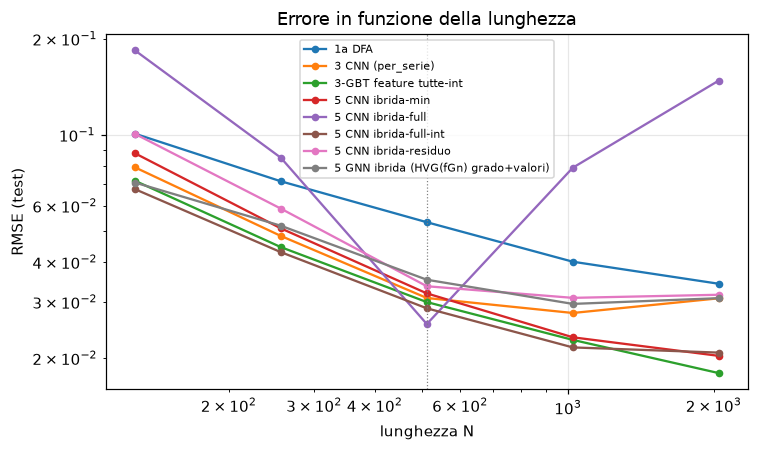

In [12]:
lengths = sorted([CFG["N"]] + list(CFG["robust_lengths"]))
split_of = {L: ("test" if L == CFG["N"] else f"test_N{L}") for L in lengths}
rob = ["1a DFA", "3 CNN (per_serie)", "3-GBT feature tutte-int", "5 CNN ibrida-min", "5 CNN ibrida-full",
       "5 CNN ibrida-full-int", "5 CNN ibrida-residuo", GNN_HYB]
rows = [{"metodo": n, "N": L, "RMSE": u.regression_metrics(H[split_of[L]], PRED[n][split_of[L]])["RMSE"]}
        for n in rob for L in lengths]
df_rob = pd.DataFrame(rows).pivot(index="metodo", columns="N", values="RMSE")
display(df_rob.round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
for n in rob:
    ax.plot(lengths, df_rob.loc[n, lengths], "o-", ms=4, label=n)
ax.axvline(CFG["N"], color="grey", lw=0.8, ls=":")
ax.set(xscale="log", yscale="log", xlabel="lunghezza N", ylabel="RMSE (test)", title="Errore in funzione della lunghezza")
ax.legend(fontsize=7); plt.tight_layout(); savefig("rmse_vs_N"); plt.show()

## 9. Salvataggio

In [13]:
mine = [n for n in PRED if n.startswith("5")]
out = Path(DATA_DIR) / f"preds05_{MODE}_seed{SEED}.npz"
np.savez_compressed(out, **{f"{n}__{s}": PRED[n][s] for n in mine for s in SPLITS},
                    **{f"STD::{n}__{s}": v for n, d in PRED_STD.items() for s, v in d.items()})
df_res.to_csv(Path(DATA_DIR) / f"results05_{MODE}.csv")
print("Salvato", out, "| tempi (s):", {k: round(v) for k, v in TIMES.items()})

Salvato data\preds05_quick_seed2026.npz | tempi (s): {'5 CNN ibrida-min': 98, '5 CNN ibrida-full': 123, '5 CNN ibrida-full-int': 122, '5 CNN ibrida-residuo': 82, '5 GNN ibrida (HVG(fGn) grado+valori)': 385}


## 10. Riepilogo

In [14]:
for a, b in [("3 CNN (per_serie)", "5 CNN ibrida-min"), ("3 CNN (per_serie)", "5 CNN ibrida-full"),
             ("3 CNN (per_serie)", "5 CNN ibrida-residuo"), ("1a DFA", "5 CNN ibrida-min"),
             ("3-GBT feature tutte", "5 CNN ibrida-full"), ("3-GBT feature tutte-int", "5 CNN ibrida-full-int"),
             ("3 CNN (per_serie)", "5 CNN ibrida-full-int"), (BEST_GNN, GNN_HYB)]:
    print(f"{b:<40} vs {a:<26}: {100 * (R[b] / R[a] - 1):+5.0f}%")

5 CNN ibrida-min                         vs 3 CNN (per_serie)         :    +3%
5 CNN ibrida-full                        vs 3 CNN (per_serie)         :   -17%
5 CNN ibrida-residuo                     vs 3 CNN (per_serie)         :    +9%
5 CNN ibrida-min                         vs 1a DFA                    :   -40%
5 CNN ibrida-full                        vs 3-GBT feature tutte       :    -3%
5 CNN ibrida-full-int                    vs 3-GBT feature tutte-int   :    -4%
5 CNN ibrida-full-int                    vs 3 CNN (per_serie)         :    -7%
5 GNN ibrida (HVG(fGn) grado+valori)     vs 4 GNN HVG(fGn) grado+valori:    -3%


### Cosa abbiamo imparato (modalità quick: N = 512, 3 semi per le CNN, 2 per la GNN)

**Tabella 2×2 (RMSE di test su H).**

| | senza feature fisiche | 4 stime fisiche | 42 feature (curve, legate a N) | 32 feature indipendenti da N |
|---|---|---|---|---|
| senza serie grezza | baseline 0.259 | GBT 0.045 | GBT 0.026 | GBT 0.030 |
| con serie grezza | CNN 0.031 | CNN ibrida-min 0.032 | CNN ibrida-full 0.026 | CNN ibrida-full-int 0.029 |

- **Le 4 stime fisiche non aggiungono nulla alla CNN a N = 512.** L'ibrida-min (0.032 [0.031, 0.033]) è alla pari con la CNN da sola (0.031 [0.030, 0.032]). La CNN estrae già dalla serie l'informazione contenuta in DFA e R/S.
- **L'ibrida-full (0.0256 [0.025, 0.026]) è la migliore in assoluto**, ma gli intervalli si sovrappongono con il GBT sulle stesse 42 feature senza serie grezza (0.0263 [0.025, 0.027]). Per la regola del corso, a parità di prestazioni vince il modello più semplice: il GBT sulle feature, senza rete convoluzionale.
- **La variante residuo** (la rete impara la correzione H − H_DFA) è peggiore (0.034). Partire dalla DFA come offset non aiuta: la correzione da imparare non è più semplice di H stesso.
- **GNN ibrida:** 0.036 → 0.035 (−3%), entro l'incertezza. Nessun guadagno chiaro.

**Il modello usa davvero la fisica? (test di permutazione).**
- Rimescolando una stima alla volta sul test, l'RMSE dell'ibrida-min sale molto per H_DFA (0.032 → 0.060) e H_R/S (→ 0.062), un po' per λ HVG (→ 0.041), e non cambia per γ NVG (0.032). Lo stimatore di Lacasa, già fallito nel notebook 02, viene ignorato.
- Rimescolandole tutte, l'RMSE arriva a 0.121, molto peggio della CNN senza stime (0.031). La rete **si appoggia** sulle stime fisiche ed è ridondante con la serie, ma non ne trae un'informazione nuova: a parità di prestazioni, ha spostato parte del lavoro sulle stime.

**Robustezza in N: qui l'ibrido fa la differenza.**
- L'ibrida-min generalizza **meglio di tutti** verso serie più lunghe: 0.023 a N = 1024 e 0.020 a N = 2048, contro 0.028 e 0.031 della CNN e 0.034 della DFA. Le stime DFA/R-S sono intensive (migliorano con N), e la rete che si appoggia su di esse eredita questa proprietà.
- L'ibrida-full **collassa** (0.148 a N = 2048), come il GBT sulle feature "tutte" (0.136, notebook 03). Le curve log F(s) e log R/S sono calcolate su scale che dipendono da N (D-30), quindi il modello impara il loro aspetto a N = 512.
- **Con le feature indipendenti da N (D-30) il collasso sparisce.** L'ibrida-full-int vale 0.068, 0.043, 0.029, 0.022, 0.021 per N = 128 … 2048: è tra i migliori a ogni lunghezza (il migliore per N ≤ 1024), anche verso serie più corte, dove ibrida-min (0.088) e CNN (0.079) sono peggiori.
- Il GBT sulle stesse 32 feature, senza serie grezza, è quasi identico: 0.072, 0.045, 0.030, 0.023, 0.018. A N = 512 l'ibrida-full-int è meglio del 4% (0.0286 [0.028, 0.030] contro 0.0299 [0.029, 0.031]), con intervalli che si toccano.

**Conclusione.**
- A lunghezza fissa, aggiungere la fisica come input migliora la CNN di poco: −7% con le 32 feature indipendenti da N, −17% con le curve legate a N, che però crollano appena N cambia. In ogni cella con feature, il GBT sulle sole feature è a pochi punti percentuali dalla CNN ibrida corrispondente.
- **Scelta per la regola del corso** (prestazioni simili → il più semplice): il **GBT sulle 32 feature indipendenti da N**. Ha la stessa accuratezza della CNN a N = 512, è più robusto della CNN a ogni altra lunghezza, si addestra in secondi e non usa l'ampiezza. La CNN ibrida-full-int è il miglior modello neurale, con un vantaggio piccolo.
- Il valore dell'informazione fisica sta soprattutto nella **robustezza**. Le stime e le pendenze sono grandezze intensive, e i modelli che le usano generalizzano a lunghezze mai viste; le curve su scale relative a N no. Il punto non è "fisica sì o no", ma **quale rappresentazione** della fisica.
- Caveat: modalità quick, pochi semi; i confronti entro ~5% non sono significativi. Numeri definitivi dalla modalità full. La forma delle feature indipendenti da N è stata scelta dopo una prova preliminare in cui si vedeva anche il test (D-30).